# Outlier Analysis & Context Report (v5.3)

**작성일**: 2026-01-11
**목적**: 이상치(Outlier)의 분포를 파악하고, 상위 이상치에 대해 **전후 문맥(Context)**을 상세히 분석합니다.

### 주요 내용
1. 이상치 유형 및 분포 시각화
2. 주요 게임 및 액션 분석
3. **Extreme Cases Deep Dive**: 상위 이상치에 대해 전후 이벤트를 포함한 상세 문맥 조회 (좌표 105x68 변환 적용)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 시각화 설정
%matplotlib inline
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

# 한글 폰트 설정 (Windows: Malgun Gothic)
try:
    plt.rcParams['font.family'] = 'Malgun Gothic'
    plt.rcParams['axes.unicode_minus'] = False
except:
    print("Warning: 한글 폰트 설정 실패")

## 1. 데이터 로드
분석을 위해 **전체 데이터**와 **이상치 목록**을 모두 로드합니다.

In [2]:
# 파일 경로
full_data_path = '../data/refined/v5.3/preprocessed_data.csv'
outlier_path = '../data/refined/v5.3/preprocessed_data_outliers.csv'

print("Loading datasets...")
df_full = pd.read_csv(full_data_path, encoding='utf-8-sig')
df_outliers = pd.read_csv(outlier_path, encoding='utf-8-sig')

print(f"Full Data: {len(df_full):,} rows")
print(f"Outlier Data: {len(df_outliers):,} rows")

# 전체 데이터 정렬 (Time 순서 보장)
df_full = df_full.sort_values(['game_id', 'period_id', 'time_seconds', 'action_id']).reset_index(drop=True)

# Index Mapping 생성 (검색 속도 향상)
index_map = dict(zip(zip(df_full['game_id'], df_full['action_id']), df_full.index))
print("Index map created.")

Loading datasets...
Full Data: 465,787 rows
Outlier Data: 3,126 rows
Index map created.


## 2. 이상치 개요 분석 (Summary)

C:\Users\user\AppData\Local\Temp\ipykernel_11268\1253832331.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='outlier_type', data=df_outliers, palette='viridis', ax=axes[0])
C:\Users\user\AppData\Local\Temp\ipykernel_11268\1253832331.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_games.index.astype(str), y=top_games.values, palette='coolwarm', ax=axes[1])


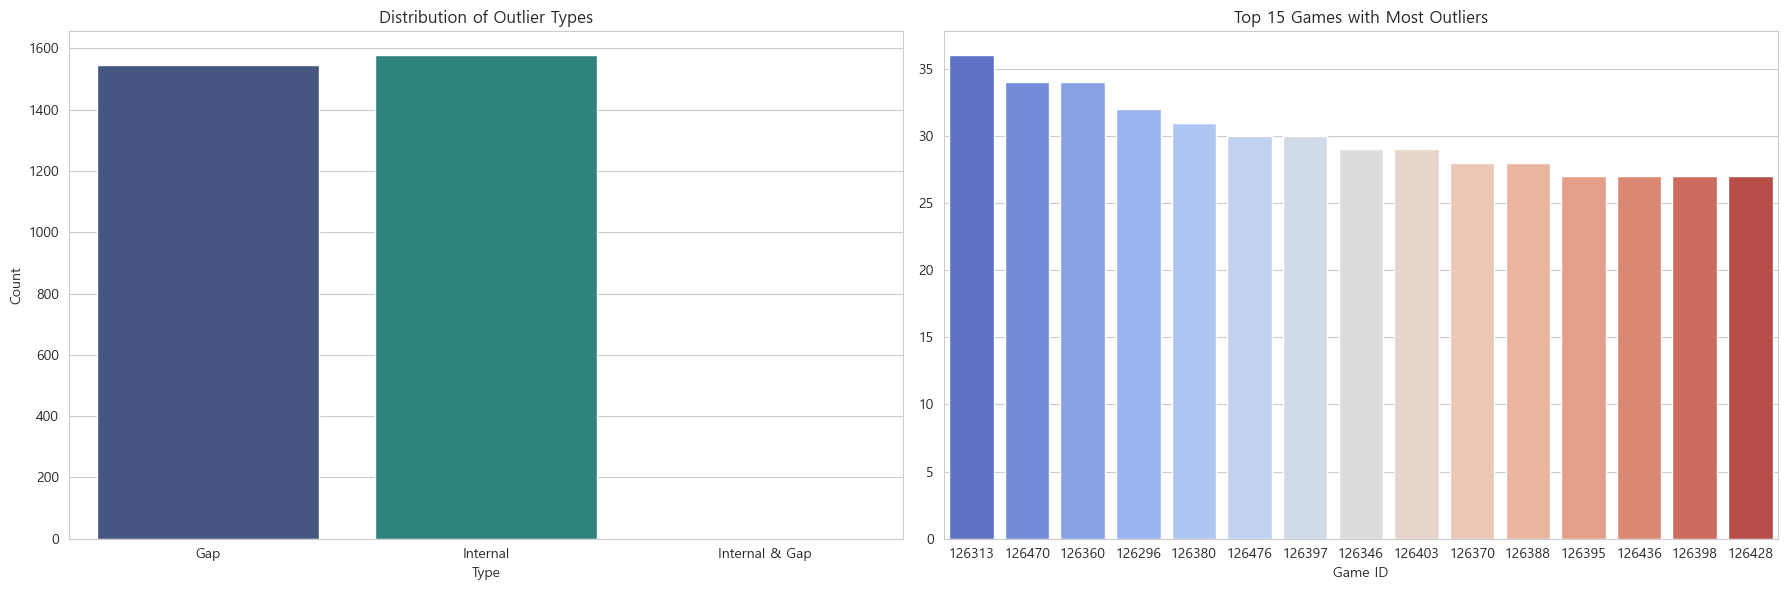

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# 1. 유형별 분포
sns.countplot(x='outlier_type', data=df_outliers, palette='viridis', ax=axes[0])
axes[0].set_title('Distribution of Outlier Types')
axes[0].set_xlabel('Type')
axes[0].set_ylabel('Count')

# 2. 게임별 Top 15
top_games = df_outliers['game_id'].value_counts().head(15)
sns.barplot(x=top_games.index.astype(str), y=top_games.values, palette='coolwarm', ax=axes[1])
axes[1].set_title('Top 15 Games with Most Outliers')
axes[1].set_xlabel('Game ID')

plt.tight_layout()
plt.show()

C:\Users\user\AppData\Local\Temp\ipykernel_11268\4280597610.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=type_counts.index, x=type_counts.values, orient='h', palette='magma')


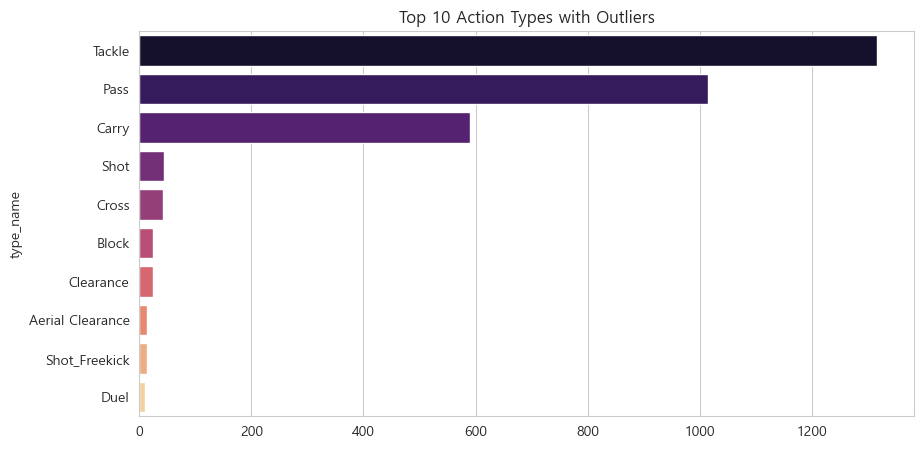

In [4]:
# 3. 액션 타입별 분포
plt.figure(figsize=(10, 5))
type_counts = df_outliers['type_name'].value_counts().head(10)
sns.barplot(y=type_counts.index, x=type_counts.values, orient='h', palette='magma')
plt.title('Top 10 Action Types with Outliers')
plt.show()

## 3. Extreme Cases with Context
이상치 이벤트의 **전후 1개 이벤트**를 포함하여 상세 정보를 조회합니다.
좌표는 `105 x 68` 미터 단위로 변환하여 출력합니다.

In [5]:
def display_outlier_context(outlier_df, full_df, idx_map, sort_col, top_n=10):
    """
    이상치 목록을 정렬하여 상위 N개에 대해 전후 문맥을 출력하는 함수
    """
    # 정렬 및 상위 추출
    target_cases = outlier_df.sort_values(sort_col, ascending=False).head(top_n)
    
    # 출력 컬럼 정의
    display_cols = ['game_id', 'time_seconds', 'dt_to_next', 'player_name_ko', 'type_name', 
                    'internal_speed', 'gap_speed', 'start_x', 'start_y', 'end_x', 'end_y']
    
    for i, (_, row) in enumerate(target_cases.iterrows()):
        game_id = row['game_id']
        action_id = row['action_id']
        
        # 전체 데이터에서 인덱스 찾기
        center_idx = idx_map.get((game_id, action_id))
        if center_idx is None:
            continue
            
        # 전후 1개 이벤트 추출 (같은 게임 내에서만)
        start_idx = max(0, center_idx - 1)
        end_idx = min(len(full_df) - 1, center_idx + 1)
        
        context_df = full_df.iloc[start_idx : end_idx + 1].copy()
        context_df = context_df[context_df['game_id'] == game_id]
        
        # Target 표시
        context_df['is_target'] = context_df['action_id'] == action_id
        
        # 좌표 변환 (0~1 -> 105x68)
        # 원본 데이터를 건드리지 않기 위해 context_df 복사본에서 수행
        context_df['start_x'] = context_df['start_x'] * 105
        context_df['start_y'] = context_df['start_y'] * 68
        context_df['end_x'] = context_df['end_x'] * 105
        context_df['end_y'] = context_df['end_y'] * 68
        
        # Outlier 정보 매핑 (전체 데이터에는 계산된 speed가 없거나 누락될 수 있으므로)
        if 'internal_speed' not in context_df.columns:
            context_df['internal_speed'] = np.nan
        if 'gap_speed' not in context_df.columns:
            context_df['gap_speed'] = np.nan
            
        # Target 행에만 outlier 정보 강제 주입 (가장 정확한 값)
        context_df.loc[context_df['is_target'], 'internal_speed'] = row['internal_speed']
        context_df.loc[context_df['is_target'], 'gap_speed'] = row['gap_speed']
        
        # 출력
        print(f"\n[Rank {i+1}] Game: {game_id} | Type: {row['outlier_type']} | {sort_col}: {row[sort_col]:.2f} m/s")
        
        # 스타일링 (Target 행 강조)
        styled = context_df[display_cols].style.apply(
            lambda x: ['background-color: #ffdddd' if v else '' for v in context_df['is_target']], 
            axis=0
        ).format("{:.2f}", subset=['internal_speed', 'gap_speed', 'start_x', 'start_y', 'end_x', 'end_y', 'time_seconds', 'dt_to_next'])
        
        display(styled)

### 3.1. Extreme Internal Speed Cases

In [ ]:
print("=== Top 10 Extreme Internal Speeds ===")
display_outlier_context(df_outliers, df_full, index_map, 'internal_speed', top_n=10)

=== Top 10 Extreme Internal Speeds ===

[Rank 1] Game: 126416 | Type: Internal | internal_speed: 33705.92 m/s


KeyError: "['dt_to_next'] not in index"

: 

### 3.2. Extreme Gap Speed Cases

In [ ]:
print("=== Top 10 Extreme Gap Speeds ===")
display_outlier_context(df_outliers, df_full, index_map, 'gap_speed', top_n=10)